In [135]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

colunas = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age",
    "Diagnosis"
]


# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [144]:
df = pd.read_csv(
    "diabetes_pima.csv_bkp",
    names=colunas
)

In [145]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Diagnosis
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [146]:
print("Dimensão:")
print(df.shape)

print("\nTipos:")
print(df.info())

print("\nDistribuição do Diagnosis:")
print(df["Diagnosis"].value_counts())

print("\nValores ausentes:")
print(df.isnull().sum())

Dimensão:
(768, 9)

Tipos:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Diagnosis                 768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB
None

Distribuição do Diagnosis:
Diagnosis
0    500
1    268
Name: count, dtype: int64

Valores ausentes:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness    

In [147]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Diagnosis,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


In [148]:
colunas_analisar = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

print("Quantidade de valores iguais a zero:\n")

for coluna in colunas_analisar:
    quantidade = (df[coluna] == 0).sum()
    percentual = quantidade / len(df) * 100

    print(
        f"{coluna:20s}: "
        f"{quantidade:3d} "
        f"({percentual:.2f}%)"
    )

Quantidade de valores iguais a zero:

Glucose             :   5 (0.65%)
BloodPressure       :  35 (4.56%)
SkinThickness       : 227 (29.56%)
Insulin             : 374 (48.70%)
BMI                 :  11 (1.43%)


### Análise de valores iguais a zero

Embora o conjunto de dados não apresente valores `NaN`, foram
identificados valores iguais a zero em variáveis nas quais esse valor
pode representar uma medição ausente ou inválida.

Foram encontrados:

- Glucose: 5 registros (0,65%)
- BloodPressure: 35 registros (4,56%)
- SkinThickness: 227 registros (29,56%)
- Insulin: 374 registros (48,70%)
- BMI: 11 registros (1,43%)

Destacam-se SkinThickness e Insulin pela elevada quantidade de valores
iguais a zero. Antes do treinamento dos modelos, esses valores deverão
ser considerados durante a etapa de tratamento dos dados.

In [149]:
variaveis = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age"
]

comparacao = df.groupby("Diagnosis")[variaveis].agg(
    ["mean", "median"]
)

comparacao.T

Diagnosis                                 0           1
Pregnancies              mean      3.298000    4.865672
                         median    2.000000    4.000000
Glucose                  mean    109.980000  141.257463
                         median  107.000000  140.000000
BloodPressure            mean     68.184000   70.824627
                         median   70.000000   74.000000
SkinThickness            mean     19.664000   22.164179
                         median   21.000000   27.000000
Insulin                  mean     68.792000  100.335821
                         median   39.000000    0.000000
BMI                      mean     30.304200   35.142537
                         median   30.050000   34.250000
DiabetesPedigreeFunction mean      0.429734    0.550500
                         median    0.336000    0.449000
Age                      mean     31.190000   37.067164
                         median   27.000000   36.000000

### Comparação das variáveis por classe

A comparação das médias e medianas entre as classes revelou diferenças
em diversas características.

A variável Glucose apresentou uma diferença expressiva, com média de
aproximadamente 109,98 para Diagnosis 0 e 141,26 para Diagnosis 1.

Também foram observadas diferenças em BMI, Age, Pregnancies e
DiabetesPedigreeFunction.

Esses resultados sugerem a existência de relações entre algumas
variáveis explicativas e a variável alvo Diagnosis.

Entretanto, variáveis como Insulin e SkinThickness apresentam grande
quantidade de valores iguais a zero, sendo necessário realizar o
tratamento desses valores antes de análises posteriores.

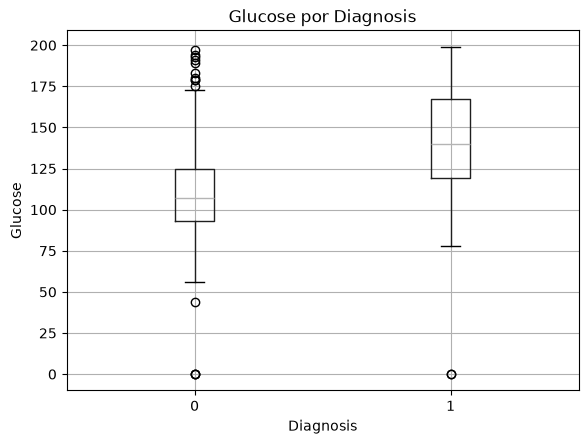

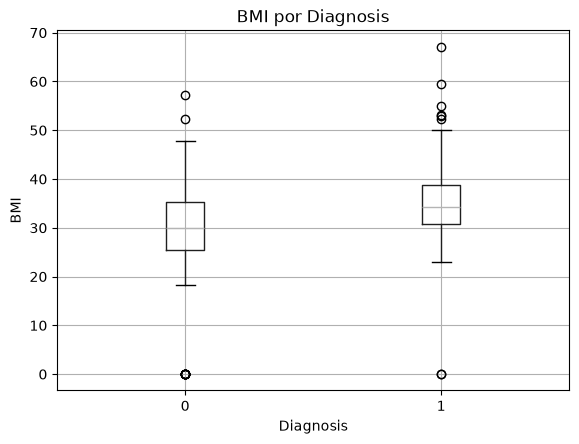

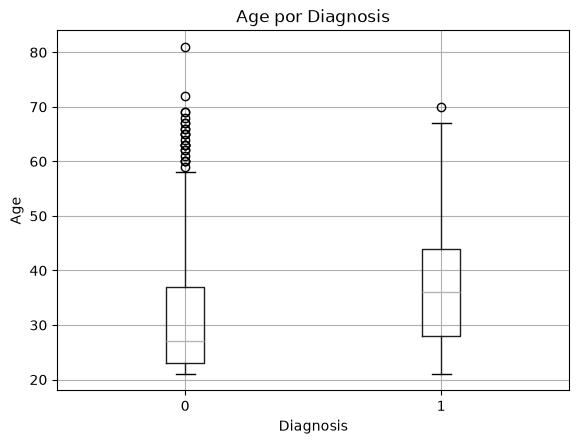

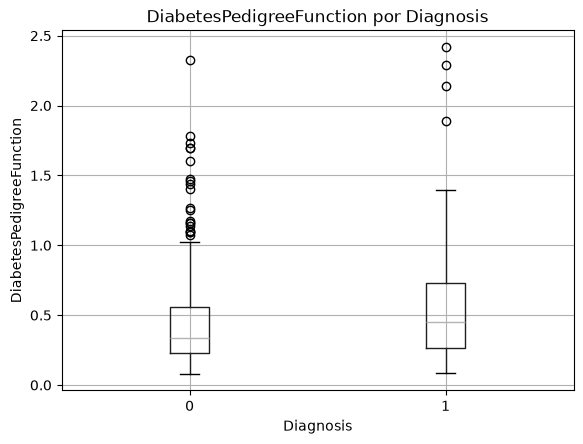

In [150]:
import matplotlib.pyplot as plt

variaveis_boxplot = [
    "Glucose",
    "BMI",
    "Age",
    "DiabetesPedigreeFunction"
]

for coluna in variaveis_boxplot:
    df.boxplot(column=coluna, by="Diagnosis")
    plt.title(f"{coluna} por Diagnosis")
    plt.suptitle("")
    plt.xlabel("Diagnosis")
    plt.ylabel(coluna)
    plt.show()

In [151]:
X = df.drop("Diagnosis", axis=1)
y = df["Diagnosis"]

print("Dimensão de X:", X.shape)
print("Dimensão de y:", y.shape)

print("\nDistribuição de y:")
print(y.value_counts())

print("\nDistribuição percentual:")
print(y.value_counts(normalize=True) * 100)

Dimensão de X: (768, 8)
Dimensão de y: (768,)

Distribuição de y:
Diagnosis
0    500
1    268
Name: count, dtype: int64

Distribuição percentual:
Diagnosis
0    65.104167
1    34.895833
Name: proportion, dtype: float64


In [152]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Dimensões:")
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

print("\nDistribuição no treino:")
print(y_train.value_counts())
print(y_train.value_counts(normalize=True) * 100)

print("\nDistribuição no teste:")
print(y_test.value_counts())
print(y_test.value_counts(normalize=True) * 100)

Dimensões:
X_train: (614, 8)
X_test : (154, 8)
y_train: (614,)
y_test : (154,)

Distribuição no treino:
Diagnosis
0    400
1    214
Name: count, dtype: int64
Diagnosis
0    65.14658
1    34.85342
Name: proportion, dtype: float64

Distribuição no teste:
Diagnosis
0    100
1     54
Name: count, dtype: int64
Diagnosis
0    64.935065
1    35.064935
Name: proportion, dtype: float64


In [153]:
X_train = X_train.copy()
X_test = X_test.copy()

colunas_zero_invalido = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

X_train[colunas_zero_invalido] = (
    X_train[colunas_zero_invalido].replace(0, np.nan)
)

X_test[colunas_zero_invalido] = (
    X_test[colunas_zero_invalido].replace(0, np.nan)
)

In [154]:
print("Valores ausentes no TREINO:")
print(X_train.isnull().sum())

print("\nValores ausentes no TESTE:")
print(X_test.isnull().sum())

Valores ausentes no TREINO:
Pregnancies                   0
Glucose                       4
BloodPressure                23
SkinThickness               175
Insulin                     290
BMI                           9
DiabetesPedigreeFunction      0
Age                           0
dtype: int64

Valores ausentes no TESTE:
Pregnancies                  0
Glucose                      1
BloodPressure               12
SkinThickness               52
Insulin                     84
BMI                          2
DiabetesPedigreeFunction     0
Age                          0
dtype: int64


In [155]:
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(strategy="median")
imputer.fit(X_train)

,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto account for missingness despite imputation. If a feature has nomissing values at fit/train time, the feature won't appear onthe missing indicator even if there are missing values attransform/test time.",False
,"keep_empty_features keep_empty_features: bool, default=FalseIf True, features that consist exclusively of missing values when`fit` is called are returned in results when `transform` is called.The imputed value is always `0` except when `strategy=""constant""`in which case `fill_value` will be used instead... versionadded:: 1.2",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](8,)","['Pregnancies','Glucose','BloodPressure',...,'BMI', 'DiabetesPedigreeFunction','Age']"
indicator_ indicator_: :class:`~sklearn.impute.MissingIndicator`Indicator used to add binary indicators for missing values.`None` if `add_indicator=False`.,NoneType,None
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,8
"statistics_ statistics_: array of shape (n_features,)The imputation fill value for each feature.Computing statistics can result in `np.nan` values.During :meth:`transform`, features corresponding to `np.nan`statistics will be discarded.","ndarray[float64](8,)","[ 3. ,117. , 72. ,..., 32.4 , 0.38, 29. ]"


In [156]:
medianas = pd.Series(
    imputer.statistics_,
    index=X_train.columns
)

print("Medianas aprendidas somente com o conjunto de treino:")
print(medianas)

Medianas aprendidas somente com o conjunto de treino:
Pregnancies                   3.0000
Glucose                     117.0000
BloodPressure                72.0000
SkinThickness                29.0000
Insulin                     125.0000
BMI                          32.4000
DiabetesPedigreeFunction      0.3825
Age                          29.0000
dtype: float64


In [157]:
X_train_imputado = imputer.transform(X_train)
X_test_imputado = imputer.transform(X_test)

In [158]:
X_train_imputado = pd.DataFrame(
    X_train_imputado,
    columns=X_train.columns,
    index=X_train.index
)

X_test_imputado = pd.DataFrame(
    X_test_imputado,
    columns=X_test.columns,
    index=X_test.index
)

In [159]:
print("Valores ausentes no treino após imputação:")
print(X_train_imputado.isnull().sum())

print("\nValores ausentes no teste após imputação:")
print(X_test_imputado.isnull().sum())

Valores ausentes no treino após imputação:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
dtype: int64

Valores ausentes no teste após imputação:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
dtype: int64


In [160]:
### criando o pipline

In [161]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

pipeline_lr = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("modelo", LogisticRegression(max_iter=1000))
])

In [162]:
pipeline_lr.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['Pregnancies','Glucose','BloodPressure',...,'BMI', 'DiabetesPedigreeFunction','Age']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For str

In [163]:
y_pred_lr = pipeline_lr.predict(X_test)

y_prob_lr = pipeline_lr.predict_proba(X_test)[:, 1]

In [164]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

print("Matriz de Confusão:")
print(confusion_matrix(y_test, y_pred_lr))

print("\nMétricas:")
print(f"Accuracy : {accuracy_score(y_test, y_pred_lr):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_lr):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred_lr):.4f}")
print(f"F1-score : {f1_score(y_test, y_pred_lr):.4f}")
print(f"ROC AUC  : {roc_auc_score(y_test, y_prob_lr):.4f}")

Matriz de Confusão:
[[82 18]
 [27 27]]

Métricas:
Accuracy : 0.7078
Precision: 0.6000
Recall   : 0.5000
F1-score : 0.5455
ROC AUC  : 0.8130


### Regressão Logística - Análise dos resultados

A Regressão Logística apresentou acurácia de aproximadamente 70,78%,
com precisão de 60,00%, recall de 50,00% e F1-score de 54,55%.

A matriz de confusão mostrou que, entre os 54 casos positivos presentes
no conjunto de teste, 27 foram corretamente identificados pelo modelo,
enquanto 27 foram classificados incorretamente como negativos.

O ROC AUC obtido foi de aproximadamente 0,813, indicando que as
probabilidades produzidas pelo modelo apresentam capacidade de
discriminação entre as duas classes.

Os resultados também demonstram a importância de não avaliar um modelo
apenas pela acurácia, principalmente quando existe diferença na
proporção das classes.

In [165]:
from sklearn.tree import DecisionTreeClassifier

pipeline_dt = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("modelo", DecisionTreeClassifier(random_state=42))
])

In [166]:
pipeline_dt.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['Pregnancies','Glucose','BloodPressure',...,'BMI', 'DiabetesPedigreeFunction','Age']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string o

In [167]:
y_pred_dt = pipeline_dt.predict(X_test)

y_prob_dt = pipeline_dt.predict_proba(X_test)[:, 1]

In [168]:
print("Matriz de Confusão:")
print(confusion_matrix(y_test, y_pred_dt))

print("\nMétricas:")
print(f"Accuracy : {accuracy_score(y_test, y_pred_dt):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_dt):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred_dt):.4f}")
print(f"F1-score : {f1_score(y_test, y_pred_dt):.4f}")
print(f"ROC AUC  : {roc_auc_score(y_test, y_prob_dt):.4f}")

Matriz de Confusão:
[[79 21]
 [28 26]]

Métricas:
Accuracy : 0.6818
Precision: 0.5532
Recall   : 0.4815
F1-score : 0.5149
ROC AUC  : 0.6357


### Árvore de Decisão - Análise dos resultados

A Árvore de Decisão apresentou acurácia de aproximadamente 68,18%,
precisão de 55,32%, recall de 48,15% e F1-score de 51,49%.

Dos 54 registros positivos presentes no conjunto de teste, 26 foram
corretamente identificados, enquanto 28 foram classificados como
negativos.

O ROC AUC obtido foi de aproximadamente 0,636. Neste experimento
baseline, a Árvore de Decisão apresentou métricas inferiores às
observadas na Regressão Logística.

Como o modelo foi treinado utilizando os parâmetros padrão, esses
resultados representam apenas uma referência inicial. Posteriormente,
poderão ser avaliados diferentes hiperparâmetros utilizando validação
cruzada.

In [169]:
from sklearn.neighbors import KNeighborsClassifier

pipeline_knn = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("modelo", KNeighborsClassifier(n_neighbors=5))
])

pipeline_knn.fit(X_train, y_train)

y_pred_knn = pipeline_knn.predict(X_test)
y_prob_knn = pipeline_knn.predict_proba(X_test)[:, 1]

In [170]:
print("Matriz de Confusão:")
print(confusion_matrix(y_test, y_pred_knn))

print("\nMétricas:")
print(f"Accuracy : {accuracy_score(y_test, y_pred_knn):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_knn):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred_knn):.4f}")
print(f"F1-score : {f1_score(y_test, y_pred_knn):.4f}")
print(f"ROC AUC  : {roc_auc_score(y_test, y_prob_knn):.4f}")

Matriz de Confusão:
[[83 17]
 [21 33]]

Métricas:
Accuracy : 0.7532
Precision: 0.6600
Recall   : 0.6111
F1-score : 0.6346
ROC AUC  : 0.7899


In [172]:

resultados_baseline = pd.DataFrame({
    "Modelo": [
        "Regressão Logística",
        "Árvore de Decisão",
        "KNN"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_dt),
        accuracy_score(y_test, y_pred_knn)
    ],
    "Precision": [
        precision_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_dt),
        precision_score(y_test, y_pred_knn)
    ],
    "Recall": [
        recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_dt),
        recall_score(y_test, y_pred_knn)
    ],
    "F1": [
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_dt),
        f1_score(y_test, y_pred_knn)
    ],
    "ROC_AUC": [
        roc_auc_score(y_test, y_prob_lr),
        roc_auc_score(y_test, y_prob_dt),
        roc_auc_score(y_test, y_prob_knn)
    ]
})

resultados_baseline.round(4)

,Modelo,Accuracy,Precision,Recall,F1,ROC_AUC
0,Regressão Logística,0.7078,0.6000,0.5000,0.5455,0.8130
1,Árvore de Decisão,0.6818,0.5532,0.4815,0.5149,0.6357
2,KNN,0.7532,0.6600,0.6111,0.6346,0.7899
